# 00 · Baseline: word + char TF-IDF → logistic regression

**Owner:** Allen
**Report section:** Model comparison (baseline row); Introduction

**Goal.** End-to-end reference pipeline: validation AUROC, 5-fold CV AUROC, saved predictions for ensembling, and a first Kaggle submission file.

Run with *Restart & Run All*. Set `QUICK = True` for a fast debug pass on the 2,000-row
starter file, `QUICK = False` for the numbers that go in the report. Every result uses the
shared split from `src.data.get_split()` (seed 42), so numbers are comparable across notebooks.

**Outputs:** `results/baseline.csv`, `results/preds_baseline.csv`, `figures/roc_baseline.png`, `submissions/submission_*_baseline.csv`.

In [1]:
# --- setup: make `src/` importable from anywhere (repo root, notebooks/, Kaggle/Colab clone) ---
import sys, time
from pathlib import Path

ROOT = Path.cwd().resolve()
while not (ROOT / "src").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

QUICK = False  # True: 2,000-row starter file for fast debugging. False: full data (report numbers).

In [2]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import SEED, set_seed, RESULTS_DIR, FIGURES_DIR
from src.data import get_split, load_test, load_unlabeled, load_train, get_cv_folds, xy
from src.features import build_features
from src.models import make_model
from src.evaluate import (auroc, cross_val_auroc, plot_roc, savefig, log_result,
                          save_predictions, predict_proba1)

set_seed(SEED)
SUFFIX = "_quick" if QUICK else ""   # keeps QUICK-mode outputs separate from real ones
from src.evaluate import write_submission

In [3]:
train_df, val_df = get_split(quick=QUICK)
test_df = load_test()
X_tr, y_tr = xy(train_df)
X_va, y_va = xy(val_df)

[train] raw=10000 empty=0 dup_rows=0 conflicting_label_rows=0 dropped=0 final=10000 (clean=True)
split: train=8000 (AI=0.500)  val=2000 (AI=0.500)  quick=False clean=True


[test] raw=3000 empty=0 dup_rows=0 conflicting_label_rows=0 dropped=0 final=3000 (clean=True)


## 1. Fit on the train split, score the validation split

Pipeline(steps=[('features',
                 FeatureUnion(transformer_list=[('word',
                                                 TfidfVectorizer(dtype=<class 'numpy.float32'>,
                                                                 min_df=2,
                                                                 ngram_range=(1,
                                                                              2),
                                                                 sublinear_tf=True,
                                                                 token_pattern='(?u)\\b\\w+\\b|[^\\w\\s]')),
                                                ('char',
                                                 TfidfVectorizer(analyzer='char_wb',
                                                                 dtype=<class 'numpy.float32'>,
                                                                 lowercase=False,
                                                                 mi

val AUROC = 0.9563   fit time = 7.1s   features = 389,790


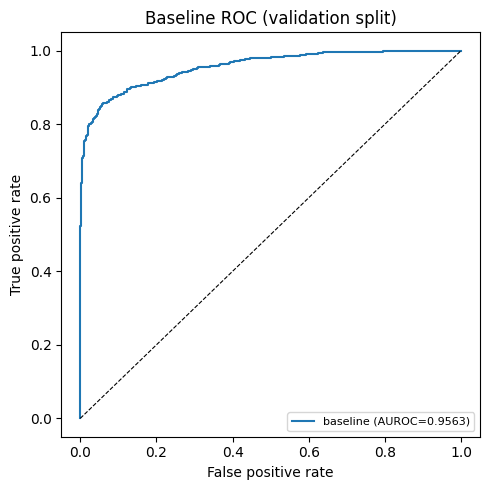

In [4]:
model = make_model("baseline")
print(model)

t0 = time.time()
model.fit(X_tr, y_tr)
fit_s = time.time() - t0
val_probs = predict_proba1(model, X_va)
val_auc = auroc(y_va, val_probs)
n_feats = model.named_steps["features"].transform(X_va[:1]).shape[1]
print(f"val AUROC = {val_auc:.4f}   fit time = {fit_s:.1f}s   features = {n_feats:,}")
plot_roc(y_va, val_probs, "baseline" + SUFFIX, title="Baseline ROC (validation split)");

## 2. 5-fold cross-validated AUROC on all labelled data

Stratified folds (seed 42); exact-duplicate texts are kept in the same fold.

In [5]:
full_df = pd.concat([train_df, val_df], ignore_index=True)
t0 = time.time()
cv = cross_val_auroc(make_model("baseline"), full_df["text"], full_df["label"], verbose=True)
cv_s = time.time() - t0
print(f"5-fold CV AUROC = {cv['cv_auroc_mean']:.4f} ± {cv['cv_auroc_std']:.4f}   ({cv_s:.0f}s)")

  fold 0: AUROC=0.9532


  fold 1: AUROC=0.9547


  fold 2: AUROC=0.9548


  fold 3: AUROC=0.9548


  fold 4: AUROC=0.9522
5-fold CV AUROC = 0.9539 ± 0.0011   (49s)


## 3. Refit on all labelled data → test predictions → submission

In [6]:
final = make_model("baseline").fit(full_df["text"], full_df["label"])
test_probs = predict_proba1(final, test_df["text"])

save_predictions("baseline" + SUFFIX, val_df, val_probs, test_df, test_probs)
sub_path = write_submission(test_df, test_probs, tag="baseline" + SUFFIX)
pd.read_csv(sub_path).describe()

saved results/preds_baseline.csv
wrote submissions/submission_20261107_170135_baseline.csv (3000 rows) - validated OK


,id,label
count,3000.000000,3000.000000
mean,14500.500000,0.457551
std,866.169729,0.253861
min,13001.000000,0.016167
25%,13750.750000,0.256697
50%,14500.500000,0.408511
75%,15250.250000,0.650232
max,16000.000000,0.990537


In [7]:
log_result("baseline", config={"model": "baseline", "features": "word+char", "clf": "logreg C=1",
                              "quick": QUICK, "n_train": len(train_df), "n_val": len(val_df)},
           metrics={"val_auroc": val_auc, **cv, "fit_seconds": round(fit_s, 1),
                    "cv_seconds": round(cv_s, 1), "n_features": n_feats})

,timestamp,git_commit,model,features,clf,quick,n_train,n_val,val_auroc,cv_auroc_mean,cv_auroc_std,cv_auroc_folds,fit_seconds,cv_seconds,n_features
0,2026-11-07T17:01:35,5c3f802,baseline,word+char,logreg C=1,False,8000,2000,0.956313,0.953932,0.001084,"[0.95316, 0.9547, 0.95482, 0.95481, 0.95217]",7.1,48.8,389790


## Notes

* Test probabilities come from the model refit on *all* labelled rows. Validation
  probabilities come from the train-split model, so they are honest held-out scores.
* `test.csv` contains styles and domains not seen in train, so validation AUROC is likely
  optimistic. See `21_generalization.ipynb`.